Entropy: 1.459147917027245

 Model 1
Cross Entropy: 1.465976547203296
KL Divergence: 0.006828630176051258
H + KL: 1.4659765472032962

 Model 2
Cross Entropy: 1.5986197610732584
KL Divergence: 0.1394718440460138
H + KL: 1.5986197610732589

Verification:
Model 1: True
Model 2: True

KL(P||Q): 0.5713915721107165
KL(Q||P): 0.5269790471552184


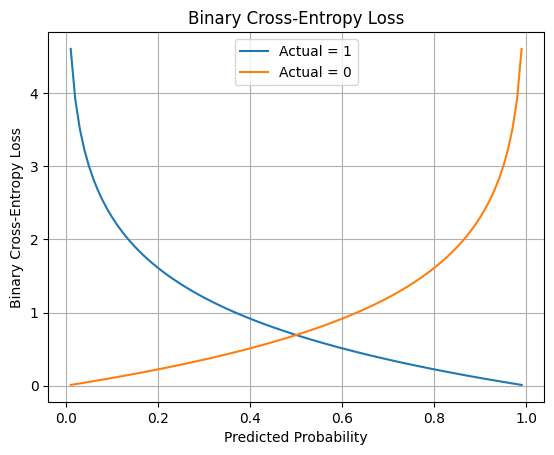

In [5]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# 1. Observed Weather Distribution (30 Days)
true = np.array([15, 10, 5]) / 30

# 2. Two Forecast Models
model1 = np.array([0.5, 0.3, 0.2])
model2 = np.array([0.3, 0.4, 0.3])

# 3. Entropy
H = entropy(true, base=2)
print("Entropy:", H)

# 4. Cross Entropy and KL Divergence
for name, model in [("Model 1", model1),
                    ("Model 2", model2)]:
    CE = -np.sum(true * np.log2(model))
    KL = entropy(true, model, base=2)

    print("\n", name)
    print("Cross Entropy:", CE)
    print("KL Divergence:", KL)
    print("H + KL:", H + KL)

# 5. Verify Cross Entropy
print("\nVerification:")
print("Model 1:", np.isclose(
    -np.sum(true*np.log2(model1)),
    H + entropy(true, model1, base=2)))

print("Model 2:", np.isclose(
    -np.sum(true*np.log2(model2)),
    H + entropy(true, model2, base=2)))

# 6. KL Divergence Asymmetry
P = np.array([0.6, 0.3, 0.1])
Q = np.array([0.2, 0.5, 0.3])

print("\nKL(P||Q):", entropy(P, Q, base=2))
print("KL(Q||P):", entropy(Q, P, base=2))

# 7. Binary Cross Entropy Loss
p = np.linspace(0.01, 0.99, 100)

loss1 = -np.log(p)       # Actual class = 1
loss0 = -np.log(1-p)     # Actual class = 0

plt.plot(p, loss1, label="Actual = 1")
plt.plot(p, loss0, label="Actual = 0")
plt.xlabel("Predicted Probability")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Binary Cross-Entropy Loss")
plt.legend()
plt.grid()
plt.show()
